In [2]:
using Pkg; Pkg.activate(@__DIR__)

  Activating project at `~/research/drag_cross_track_formation/zacs-drag-formation`


In [3]:
using Plots
using JLD2
using LaTeXStrings
pgfplotsx()
# gr()

Plots.PGFPlotsXBackend()

In [4]:
const Re_mks = 6378.137 #Radius of the Earth (km)
const alt_line = 440# 550#440
const a_mks_line = Re_mks + alt_line #semi-major axis (km)


6818.137

In [5]:
data_line = load_object("Data/4sat_Jeffects_rot_eccen_control1_Line.jld2")

([0.0 0.0 0.0; 2.6569699506794864e-5 2.6569699506794864e-5 2.6569699506794864e-5; … ; -0.0002937000133908735 -0.00021399328424393692 -0.0038826408587567065; -0.0002678111833863423 -0.0001414602097075966 -0.0037282718655590606], [0.0 0.0 0.0; -5.58917787230051e-6 -5.58917787230051e-6 -5.58917787230051e-6; … ; -5.221686105727485e-7 -5.01173422207124e-7 -2.6843535680942665e-6; -5.450658846495315e-7 -4.899524784773845e-7 -2.6646028273846767e-6], [0.0 0.0 0.0; -3.126275149867297e-8 -3.126275149867297e-8 -3.126275149867297e-8; … ; -0.013090769511828526 -0.026201389226585547 -0.039340667398255036; -0.013091712031226166 -0.026203313184342214 -0.039343154574384975], [0.0 0.0 0.0; -3.126275149867297e-8 -3.126275149867297e-8 -3.126275149867297e-8; … ; -0.013090769511828526 -0.026201389226585547 -0.039340667398255036; -0.013091712031226166 -0.026203313184342214 -0.039343154574384975], [0.2 0.2 0.2; 0.2 0.2 0.2; … ; 0.2 0.2 0.2; 0.2 0.2 0.2], [1.0 1.0 1.0; 1.0 1.0 1.0; … ; 0.20214869209963318 0.2 0

In [6]:
Δθhist_line, Δahist_line, ΔΩhist_line, ΔΩhist_old_line, u1hist_line, u2hist_line, a1hist_line, a2hist_line, θ1hist_line, θ2hist_line, Ω1hist_line, Ω2hist_line, tp_hist_line, Δθunhist_line, x_hist_line, t_hist_line, params_line = data_line
# Δθhist_line, Δahist_line, ΔΩhist_line, u1hist_line, u2hist_line, a1hist_line, a2hist_line, θ1hist_line, θ2hist_line, Ω1hist_line, Ω2hist_line, tp_hist_line, Δθunhist_line, x_hist_line, t_hist_line, params_line = data_line

@show size(Δθhist_line)
@show size(Δahist_line)
@show size(ΔΩhist_line)
@show size(u1hist_line)
@show size(u2hist_line)
@show size(a1hist_line)
@show size(a2hist_line)
@show size(θ1hist_line)
@show size(θ2hist_line)
@show size(Ω1hist_line)
@show size(Ω2hist_line)
@show size(tp_hist_line)
@show size(Δθunhist_line)
@show size(x_hist_line)
@show size(t_hist_line)
@show params_line

sample_steps = 10
downsample_line = [i % sample_steps == 0 for i = 0:length(tp_hist_line)-1]
downsample_line[end] = 1

size(Δθhist_line) = (1400, 3)
size(Δahist_line) = (1400, 3)
size(ΔΩhist_line) = (1400, 3)
size(u1hist_line) = (1400, 3)
size(u2hist_line) = (1400, 3)
size(a1hist_line) = (1400, 3)
size(a2hist_line) = (1400, 3)
size(θ1hist_line) = (1400, 3)
size(θ2hist_line) = (1400, 3)
size(Ω1hist_line) = (1400, 3)
size(Ω2hist_line) = (1400, 3)
size(tp_hist_line) = (1, 1400)
size(Δθunhist_line) = (1400, 3)
size(x_hist_line) = (36, 261613)
size(t_hist_line) = (1, 261613)
params_line = (l_12 = 1, l_13 = 2, l_14 = 3, l_15 = 4.0, l_16 = 5.0, Δx0 = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], Δaf = 0, u_min = 0.2, u_max = 1.0, Δa_min = -0.014666763076189289, Δa_max = 0.014666763076189289, Δθf = [6.283185307179586, 12.566370614359172, 18.84955592153876, 25.132741228718345, 31.41592653589793], ΔΩf = [-0.012969814874210828, -0.025939629748421657, -0.03890944462263249, -0.051879259496843314, -0.06484907437105414])


1

In [7]:
num_sat = size(Δθhist_line)[2] + 1
mylabel_line = String[]
mylabel1_line = String[]
mylabel2_line = String[]
for i = 1:num_sat
    append!(mylabel_line,["Sat. 1-"*string(i+1)])
    append!(mylabel1_line,["Sat. 1"])
    append!(mylabel2_line,["Sat. "*string(i+1)])
end

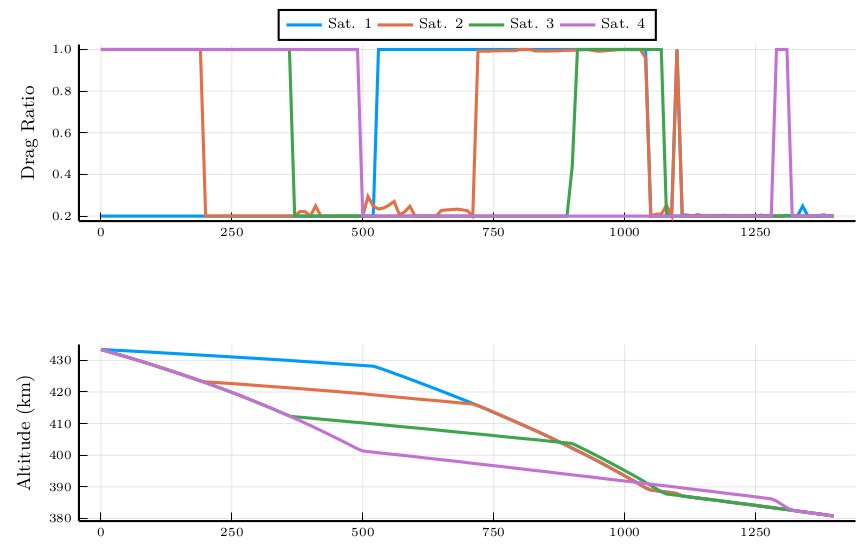

In [8]:
pl1_line = plot(tp_hist_line[downsample_line],u1hist_line[downsample_line,1],label=permutedims(mylabel1_line), linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true, legend_columns=-1)#,legend=:"best") #,ls=:dot
plot!(tp_hist_line[downsample_line],u2hist_line[downsample_line,:],label=permutedims(mylabel2_line), linewidth=1.5) #,ls=:dot
plot!(xlabel=nothing, ylabel = "Drag Ratio")#,legend=:"best", xtickfontsize=18, ytickfontsize=18)"Orbit Number"

pl2_line = plot(tp_hist_line[downsample_line],a1hist_line[downsample_line,1]*a_mks_line.-Re_mks,label=nothing, linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:top,legendfontsize=7, tex_output_standalone = true)#, ylim=[0, 500])#,legend=:"best") #,ls=:dot
plot!(tp_hist_line[downsample_line],a2hist_line[downsample_line,:]*a_mks_line.-Re_mks,label=nothing, linewidth=1.5)
plot!(xlabel=nothing, ylabel = "Altitude (km)")#,legend=:"best", xtickfontsize=18, ytickfontsize=18)

pl3_line = plot(tp_hist_line[downsample_line],broadcast.(rad2deg,ΔΩhist_line[downsample_line,:]),label=permutedims(mylabel_line), linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true,legend_columns=-1)
plot!(xlabel=nothing, ylabel = L"$\Delta \Omega$ (deg)")

pl4_line = plot(tp_hist_line[downsample_line],broadcast.(rad2deg,Δθhist_line[downsample_line,:]),label=nothing, linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true,legend_columns=-1)
plot!(xlabel="Orbit Number", ylabel = L"$\Delta \theta$ (deg)", yticks = [90*i for i = -2:3])#"\$\\Delta \\bar{\\theta}, deg\$")


pl_line1 = plot(pl1_line,pl2_line, layout = (2,1), margins=(10,:px), size=(300,170), tex_output_standalone = false)
pl_line1_pres = plot(pl1_line,pl2_line, layout = (2,1), margins=(10,:px), tex_output_standalone = false)

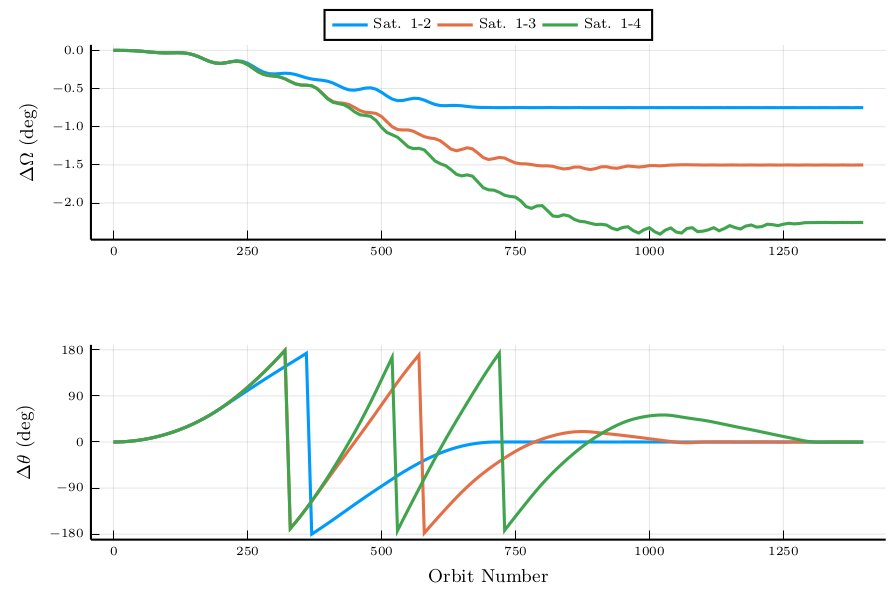

In [11]:
pl_line2 = plot(pl3_line,pl4_line, layout = (2,1), margins=(10,:px), size=(300,170), tex_output_standalone = false)
pl_line2_pres = plot(pl3_line,pl4_line, layout = (2,1), tex_output_standalone = false)

In [12]:
savefig(pl_line1, "Plots/ResultsLine_1.tex")
savefig(pl_line1_pres, "Plots/ResultsLine_1.pdf")
savefig(pl_line1, "Plots/ResultsLine_1.tikz")

savefig(pl_line2, "Plots/ResultsLine_2.tex")
savefig(pl_line2_pres, "Plots/ResultsLine_2.pdf")
savefig(pl_line2, "Plots/ResultsLine_2.tikz")

"/Users/jbwillis/research/drag_cross_track_formation/zacs-drag-formation/Plots/ResultsLine_2.tikz"

In [13]:
tp_hist_line[end]

1399.0

-------
# Box Scenario

In [14]:
const alt_box = 550# 550#440
const a_mks_box = Re_mks + alt_box #semi-major axis (km)

6928.137

In [15]:
data_box = load_object("Data/4sat_Jeffects_rot_eccen_control1_Box.jld2")

Δθhist_box, Δahist_box, ΔΩhist_box, u1hist_box, u2hist_box, a1hist_box, a2hist_box, θ1hist_box, θ2hist_box, Ω1hist_box, Ω2hist_box, tp_hist_box, Δθunhist_box, x_hist_box, t_hist_box, params_box = data_box

@show size(Δθhist_box)
@show size(Δahist_box)
@show size(ΔΩhist_box)
@show size(u1hist_box)
@show size(u2hist_box)
@show size(a1hist_box)
@show size(a2hist_box)
@show size(θ1hist_box)
@show size(θ2hist_box)
@show size(Ω1hist_box)
@show size(Ω2hist_box)
@show size(tp_hist_box)
@show size(Δθunhist_box)
@show size(x_hist_box)
@show size(t_hist_box)
@show params_box

sample_steps = 10
downsample_box = [i % sample_steps == 0 for i = 0:length(tp_hist_box)-1]
downsample_box[end] = 1


size(Δθhist_box) = (4934, 3)
size(Δahist_box) = (4934, 3)
size(ΔΩhist_box) = (4934, 3)
size(u1hist_box) = (4934, 3)
size(u2hist_box) = (4934, 3)
size(a1hist_box) = (4934, 3)
size(a2hist_box) = (4934, 3)
size(θ1hist_box) = (4934, 3)
size(θ2hist_box) = (4934, 3)
size(Ω1hist_box) = (4934, 3)
size(Ω2hist_box) = (4934, 3)
size(tp_hist_box) = (4934,)
size(Δθunhist_box) = (4934, 3)
size(x_hist_box) = (36, 947136)
size(t_hist_box) = (1, 947136)
params_box = (l_12 = 0.03, l_13 = 6.0, l_14 = 6.03, l_15 = 4.0, l_16 = 5.0, Δx0 = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], Δaf = 0, u_min = 0.2, u_max = 1.0, Δa_min = -0.01443389471080032, Δa_max = 0.01443389471080032, Δθf = [0.18849555921538758, 37.69911184307752, 37.88760740229291, 25.132741228718345, 31.41592653589793], ΔΩf = [8.424793830301574e-5, 0.016849587660603148, 0.016933835598906165, 0.011233058440402099, 0.014041323050502624])


1

In [16]:
num_sat = size(Δθhist_box)[2] + 1
mylabel_box = String[]
mylabel1_box = String[]
mylabel2_box = String[]
for i = 1:num_sat
    append!(mylabel_box,["Sat. 1-"*string(i+1)])
    append!(mylabel1_box,["Sat. 1"])
    append!(mylabel2_box,["Sat. "*string(i+1)])
end

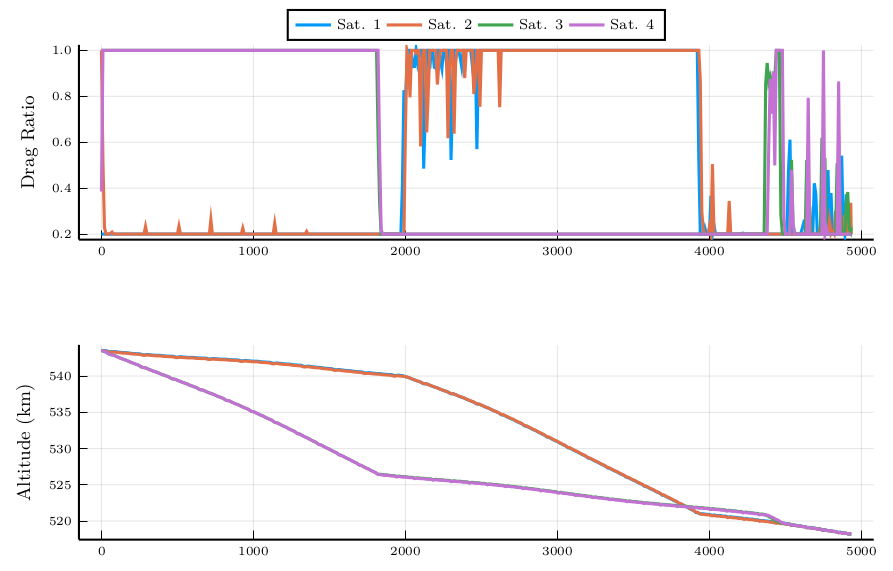

In [17]:
pl1_box = plot(tp_hist_box[downsample_box],u1hist_box[downsample_box,1],label=permutedims(mylabel1_box), linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true, legend_columns=-1)#,legend=:"best") #,ls=:dot
plot!(tp_hist_box[downsample_box],u2hist_box[downsample_box,:],label=permutedims(mylabel2_box), linewidth=1.5) #,ls=:dot
plot!(xlabel=nothing, ylabel = "Drag Ratio")#,legend=:"best", xtickfontsize=18, ytickfontsize=18)"Orbit Number"

pl2_box = plot(tp_hist_box[downsample_box],a1hist_box[downsample_box,1]*a_mks_box.-Re_mks,label=nothing, linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:top,legendfontsize=7, tex_output_standalone = true)#, ylim=[0, 500])#,legend=:"best") #,ls=:dot
plot!(tp_hist_box[downsample_box],a2hist_box[downsample_box,:]*a_mks_box.-Re_mks,label=nothing, linewidth=1.5)
plot!(xlabel=nothing, ylabel = "Altitude (km)")#,legend=:"best", xtickfontsize=18, ytickfontsize=18)

pl3_box = plot(tp_hist_box[downsample_box],broadcast.(rad2deg,ΔΩhist_box[downsample_box,:]),label=permutedims(mylabel_box), linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true,legend_columns=-1)
plot!(xlabel=nothing, ylabel = L"$\Delta \Omega$ (deg)")

pl4_box = plot(tp_hist_box[downsample_box],broadcast.(rad2deg,Δθhist_box[downsample_box,:]),label=nothing, linewidth=1.5, xtickfontsize=6, ytickfontsize=6,yguidefontsize=9,xguidefontsize=9,legend=:outertop,legendfontsize=7, tex_output_standalone = true,legend_columns=-1)
plot!(xlabel="Orbit Number", ylabel = L"$\Delta \theta$ (deg)", yticks = [90*i for i = -2:3])#"\$\\Delta \\bar{\\theta}, deg\$")


pl_box1 = plot(pl1_box,pl2_box, layout = (2,1), margins=(10,:px), size=(300,170), tex_output_standalone = false)
pl_box1_pres = plot(pl1_box,pl2_box, layout = (2,1), tex_output_standalone = false)

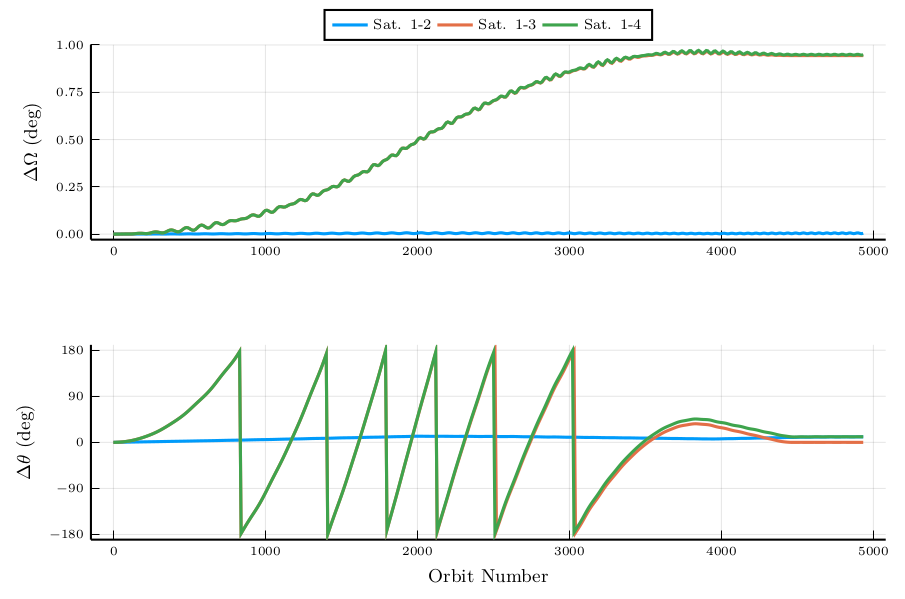

In [18]:
pl_box2 = plot(pl3_box,pl4_box, layout = (2,1), margins=(10,:px), size=(300,170), tex_output_standalone = false)
pl_box2_pres = plot(pl3_box,pl4_box, layout = (2,1), tex_output_standalone = false)

In [19]:
savefig(pl_box1, "Plots/ResultsBox_1.tex")
savefig(pl_box1_pres, "Plots/ResultsBox_1.pdf")
savefig(pl_box1, "Plots/ResultsBox_1.tikz")

savefig(pl_box2, "Plots/ResultsBox_2.tex")
savefig(pl_box2_pres, "Plots/ResultsBox_2.pdf")
savefig(pl_box2, "Plots/ResultsBox_2.tikz")

"/Users/jbwillis/research/drag_cross_track_formation/zacs-drag-formation/Plots/ResultsBox_2.tikz"

In [17]:
6885.55 - Re_mks

507.41300000000047

In [18]:
6763.6 - Re_mks

385.46300000000065

-----
# Distance between satellites

With the angle between them given as $\theta$, and the altitude of satellite 1 as $a_1$ and satellite 2 as $a_2$ the straight-line distance between the two satellites is given by the law of cosines

$$
d^2 = a_1^2 + a_2^2 - 2 a_1 a_2 \cos(\theta)
$$

In [38]:
distances_Ω_line = ((a1hist_line.*a_mks_line).*sqrt.(2 .- 2 .*cos.(ΔΩhist_line)))
distances_θ_line = ((a1hist_line.*a_mks_line).*sqrt.(2 .- 2 .*cos.(Δθhist_line)))
distances_line = sqrt.(distances_Ω_line.^2 .+ distances_θ_line.^2)

p = plot(tp_hist_line[downsample_line], distances_line[downsample_line,:], label=permutedims(mylabel_line), xlabel="Orbit Number", ylabel="Distance (km)", title="Line Scenario Distances")
plot!(p, [tp_hist_line[1], tp_hist_line[end]], 500 * ones(2), style=:dash, color=:red, label="")
savefig(p, "Plots/Distance_Line.pdf")

"/Users/jbwillis/research/drag_cross_track_formation/zacs-drag-formation/Plots/Distance_Line.pdf"

In [39]:
distances_Ω_box = ((a1hist_box.*a_mks_box).*sqrt.(2 .- 2 .*cos.(ΔΩhist_box)))
distances_θ_box = ((a1hist_box.*a_mks_box).*sqrt.(2 .- 2 .*cos.(Δθhist_box)))
distances_box = sqrt.(distances_Ω_box.^2 .+ distances_θ_box.^2)

p = plot(tp_hist_box[downsample_box], distances_box[downsample_box,:], label=permutedims(mylabel_box), xlabel="Orbit Number", ylabel="Distance (km)", title="Square Scenario Distances")
plot!(p, [tp_hist_box[1], tp_hist_box[end]], 500 * ones(2), style=:dash, color=:red, label="")
savefig(p, "Plots/Distance_Box.pdf")

"/Users/jbwillis/research/drag_cross_track_formation/zacs-drag-formation/Plots/Distance_Box.pdf"